In [3]:
import matplotlib.pyplot as plt
import MDAnalysis as mda
import numpy as np
import pandas as pd
from matplotlib.colors import CenteredNorm

from mg_sampling import PROJECT_DIR
from mg_sampling.density.align import reorder_residue_atoms
from mg_sampling.density.grid import Grid
from mg_sampling.density.utils import QuantileTransformation, indices_to_mask
from mg_sampling.tools import edges_to_range


/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Align two maps

In [4]:
maps = dict()

# maps['New map (2.3 Å)'] = Grid(PROJECT_DIR / 'density/emd_42498.map', file_format='mrc')
# maps['New half-map 1 (2.3 Å)'] = Grid(PROJECT_DIR / 'density/emd_42498_half_map_1.map', file_format='mrc')
# maps['New half-map 2 (2.3 Å)'] = Grid(PROJECT_DIR / 'density/emd_42498_half_map_2.map', file_format='mrc')
# maps['New average half-maps (2.3 Å)'] = (maps['New half-map 1 (2.3 Å)'] + maps['New half-map 2 (2.3 Å)']) / 2
# maps['New map (2.3 Å) unsharp.'] = maps['New map (2.3 Å)'].apply_tempfactor(74.07)

maps["New map (2.2 Å)"] = Grid(PROJECT_DIR / "density/emd_42499.mrc")
maps["New half-map 1 (2.2 Å)"] = Grid(
    PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_A.mrc"
)
maps["New half-map 2 (2.2 Å)"] = Grid(
    PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_B.mrc",
)
maps["New average half-maps (2.2 Å)"] = (
    maps["New half-map 1 (2.2 Å)"] + maps["New half-map 2 (2.2 Å)"]
) / 2
maps["New half-map 1 wrong (2.2 Å)"] = Grid(
    PROJECT_DIR / "density/emd_42499_half_map_1.mrc"
)
maps["New half-map 2 wrong (2.2 Å)"] = Grid(
    PROJECT_DIR / "density/emd_42499_half_map_2.mrc",
)
maps["New map (2.2 Å) unsharp."] = maps["New map (2.2 Å)"].apply_tempfactor(79.23)
maps["New map (2.2 Å) unsharp. Phenix"] = Grid(
    PROJECT_DIR / "density/emd_42499_unsharp_phenix.mrc",
)

maps["Old map (3.14 Å)"] = Grid(
    PROJECT_DIR / "density/emd_31385.mrc",
)

old_map = maps["Old map (3.14 Å)"]
new_map = maps["New map (2.2 Å)"]

In [5]:
u = mda.Universe(PROJECT_DIR / "structures/7EZ0_fixed.pdb")
ag = u.select_atoms("name P")
mda.analysis.rms.RMSD(ag).run()

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/analysis/base.py:562: UserWarning: Reader has no dt information, set to 1.0 ps
  self.times[idx] = ts.time
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/base.py:759: UserWarning: Reader has no dt information, set to 1.0 ps
  return self.ts.time


In [6]:
structs = dict()

structs["7ez0 (3.14 Å)"] = mda.Universe(PROJECT_DIR / "structures/7EZ0_fixed.pdb")
structs["9cbu (2.2 Å)"] = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb")
structs["9cbx (2.2 Å)"] = mda.Universe(PROJECT_DIR / "structures/9CBX_fixed.pdb")
# structs['9cbw (2.3 Å)'] = mda.Universe(PROJECT_DIR / 'structures/9CBW_fixed.pdb')
# structs['9cby (2.3 Å)'] = mda.Universe(PROJECT_DIR / 'structures/9CBY_fixed.pdb')

In [7]:
df = pd.DataFrame(
    {
        ki: {
            kj: mda.analysis.rms.rmsd(
                reorder_residue_atoms(
                    ui.select_atoms(
                        "nucleic and not type H and not (resid 22 and name P OP1 OP2)"
                    )
                ).positions,
                reorder_residue_atoms(
                    uj.select_atoms(
                        "nucleic and not type H and not (resid 22 and name P OP1 OP2)"
                    )
                ).positions,
                superposition=True,
                center=True,
            )
            for kj, uj in structs.items()
        }
        for ki, ui in structs.items()
    }
)
df.round(2)

,7ez0 (3.14 Å),9cbu (2.2 Å),9cbx (2.2 Å)
7ez0 (3.14 Å),0.00,1.61,1.61
9cbu (2.2 Å),1.61,0.00,0.00
9cbx (2.2 Å),1.61,0.00,0.00


In [8]:
# Align old to new with structures
new_ag = reorder_residue_atoms(
    structs["9cbu (2.2 Å)"].select_atoms(
        "nucleic and not type H and not (resid 22 and name P OP1 OP2)"
    )
)
old_ag = reorder_residue_atoms(
    structs["7ez0 (3.14 Å)"].select_atoms(
        "nucleic and not type H and not (resid 22 and name P OP1 OP2)"
    )
)
assert np.all(old_ag.names == new_ag.names)

vector = new_ag.center_of_mass() - old_ag.center_of_mass()

R, _ = mda.analysis.align.rotation_matrix(
    old_ag.positions - old_ag.center_of_mass(),
    new_ag.positions - new_ag.center_of_mass(),
)
point = new_ag.center_of_mass()

old_ag_aligned = mda.Merge(old_ag).atoms.translate(vector).rotate(R, point=point)

# Same for map with resample
old_map_aligned = old_map.translate_origin(vector)
old_map_aligned.interpolation_cval = 0.0
old_map_aligned = old_map_aligned.resample(new_map)
old_map_aligned.interpolation_cval = 0.0
old_map_aligned = old_map_aligned.rotate(R, point=point)

maps["Old map (3.14 Å) aligned"] = old_map_aligned
maps["Old map (3.14 Å) aligned unsharp."] = old_map_aligned.apply_tempfactor(14.0)


# new_ag = reorder_residue_atoms(structs['9cbu (2.2 Å)'].select_atoms('nucleic and not type H and not (resid 22 and name P OP1 OP2)'))
# old_ag = reorder_residue_atoms(structs['9cbw (2.3 Å)'].select_atoms('nucleic and not type H and not (resid 22 and name P OP1 OP2)'))
# assert np.all(old_ag.names == new_ag.names)

# vector = new_ag.center_of_mass() - old_ag.center_of_mass()

# R, _ = mda.analysis.align.rotation_matrix(old_ag.positions - old_ag.center_of_mass(), new_ag.positions - new_ag.center_of_mass())
# point = new_ag.center_of_mass()

# # Same for map with resample
# old_map = maps['New map (2.3 Å)']
# old_map_aligned = old_map.translate_origin(vector)
# old_map_aligned.interpolation_cval = 0.0
# old_map_aligned = old_map_aligned.resample(new_map)
# old_map_aligned.interpolation_cval = 0.0
# old_map_aligned = old_map_aligned.rotate(R, point=point)

# maps['New map (2.3 Å) aligned'] = old_map_aligned
# maps['Unsharpened new map (2.3 Å) aligned'] = old_map_aligned.apply_tempfactor(74.07)


In [9]:
from mg_sampling.density.utils import voxels_around

vox_indices = voxels_around(new_ag, 6, new_map.grid_params)
new_cc_mask = indices_to_mask(vox_indices, new_map.grid_params)


In [10]:
def plot_map_slice(
    grid: Grid,
    func: str = "imshow",
    plane="xy",
    depth=0.5,
    depth_mode="fraction",
    ax=None,
    **kwargs,
):
    if ax is None:
        ax = plt.gca()

    if isinstance(func, str):
        func = getattr(ax, func)

    x_axis, y_axis = ["xyz".index(dim) for dim in plane]
    depth_axis = ({0, 1, 2} - set((x_axis, y_axis))).pop()
    midpoints = grid.midpoints[depth_axis]
    x_edges, y_edges = grid.edges[x_axis], grid.edges[y_axis]
    extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]
    z_edges = grid.edges[depth_axis]

    if depth_mode == "fraction":
        k = int(depth * len(midpoints))
    elif depth_mode == "index":
        k = int(depth)
    elif depth_mode == "coord":
        k = int(np.searchsorted(midpoints, depth, side="left"))

    s = tuple(slice(None) if d in (x_axis, y_axis) else k for d in (0, 1, 2))

    out = func(grid.grid[s].T, origin="lower", extent=extent, **kwargs)

    ax.set_xlabel("xyz"[x_axis])
    ax.set_ylabel("xyz"[y_axis])

    return out

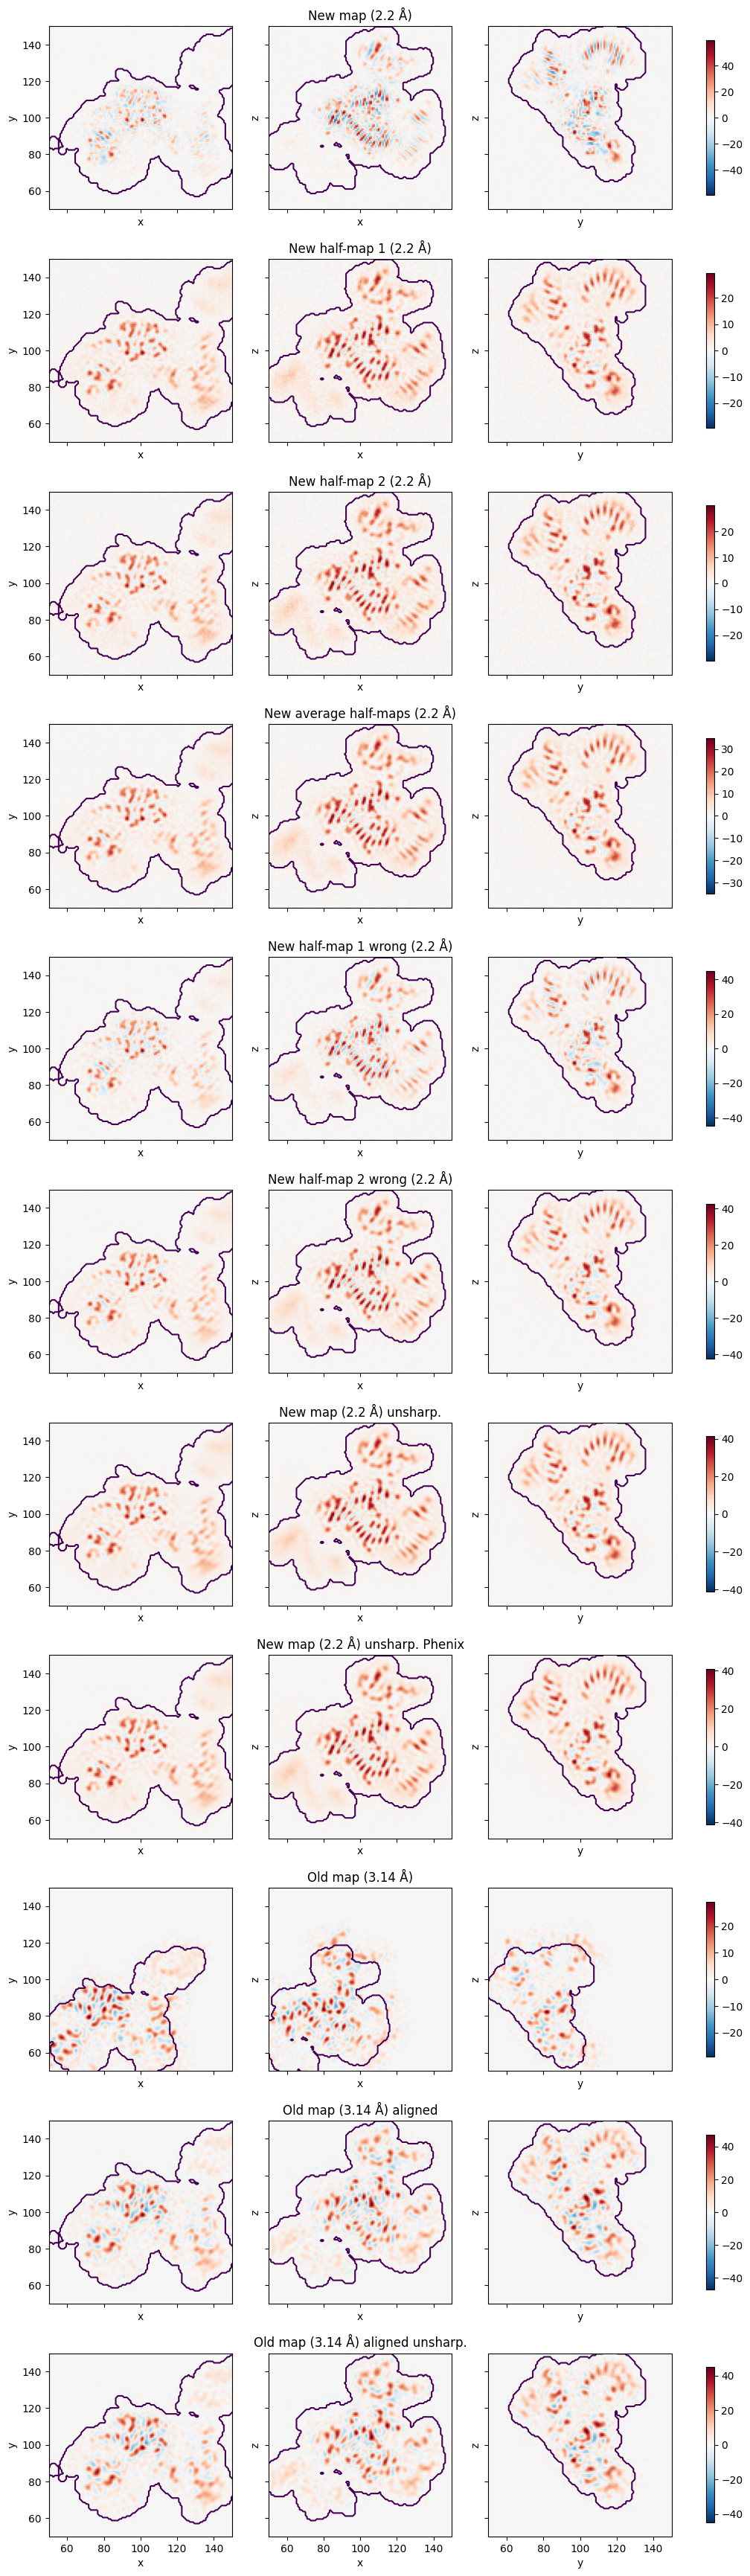

In [11]:
fig, axarr = plt.subplots(
    ncols=3, nrows=len(maps), sharex=True, sharey=True, figsize=(12, len(maps) * 4)
)

for i, plane in enumerate(("xy", "xz", "yz")):
    for v, ax in zip(maps.values(), axarr[:, i]):
        norm = CenteredNorm()
        _ = plot_map_slice(
            v / v.grid.std(), "imshow", ax=ax, plane=plane, norm=norm, cmap="RdBu_r"
        )
        _ = plot_map_slice(
            Grid(new_cc_mask, edges=v.edges),
            "contour",
            ax=ax,
            plane=plane,
            levels=[0.5],
        )

plt.gca().set_xlim(50, 150)
plt.gca().set_ylim(50, 150)
for k, ax in zip(maps.keys(), axarr[:, 1]):
    ax.set_title(k)
for axes in axarr:
    plt.colorbar(axes[0].images[0], ax=axes, shrink=0.8, fraction=0.05, aspect=20)

### Comparison between half-maps

In [11]:
import pandas as pd
from scipy.stats import linregress
from tqdm import tqdm
import itertools
# Mutual information
import infomeasure as im

def mutual_info(x, y, n_subsamples=None):
    if n_subsamples is not None:
        inds = np.random.choice(len(x), size=n_subsamples, replace=False)
        x = x[inds]
        y = y[inds]
    # Whiten data 
    x = (x - np.mean(x)) / np.std(x)
    y = (y - np.mean(y)) / np.std(y)
    return im.mutual_information(x, y, approach="metric")
    

results = []
for (ki, mapi), (kj, mapj) in tqdm(itertools.product(maps.items(), repeat=2)):
    results.append({
        'Map 1': ki,
        'Map 2': kj,
        'CC': linregress(mapi.grid[new_cc_mask], mapj.grid[new_cc_mask]).rvalue,
        'MI': mutual_info(mapi.grid[new_cc_mask], mapj.grid[new_cc_mask], n_subsamples=10000) if ki != kj else np.nan,
    })

44it [00:24,  1.80it/s]


KeyboardInterrupt: 

In [17]:
results = pd.DataFrame(results)
results.pivot(index=['Map 1'], columns=['Map 2'])['CC'].sort_index().style.background_gradient(vmin=0, vmax=1, cmap="Reds").format(precision=2)

Map 2,New average half-maps (2.2 Å),New half-map 1 (2.2 Å),New half-map 1 wrong (2.2 Å),New half-map 2 (2.2 Å),New half-map 2 wrong (2.2 Å),New map (2.2 Å),New map (2.2 Å) unsharp.,New map (2.2 Å) unsharp. Phenix,Old map (3.14 Å)
Map 1,,,,,,,,,
New average half-maps (2.2 Å),1.00,0.99,0.94,0.99,0.98,0.78,0.99,0.99,0.04
New half-map 1 (2.2 Å),0.99,1.00,0.94,0.94,0.96,0.77,0.97,0.97,0.04
New half-map 1 wrong (2.2 Å),0.94,0.94,1.00,0.92,0.95,0.92,0.95,0.94,0.03
New half-map 2 (2.2 Å),0.99,0.94,0.92,1.00,0.98,0.77,0.97,0.97,0.04
New half-map 2 wrong (2.2 Å),0.98,0.96,0.95,0.98,1.00,0.83,0.99,0.99,0.03
New map (2.2 Å),0.78,0.77,0.92,0.77,0.83,1.00,0.77,0.77,0.01
New map (2.2 Å) unsharp.,0.99,0.97,0.95,0.97,0.99,0.77,1.00,1.00,0.04
New map (2.2 Å) unsharp. Phenix,0.99,0.97,0.94,0.97,0.99,0.77,1.00,1.00,0.04
Old map (3.14 Å),0.04,0.04,0.03,0.04,0.03,0.01,0.04,0.04,1.00


In [18]:
results.pivot(index=['Map 1'], columns=['Map 2'])['MI'].sort_index().style.background_gradient(vmin=0, vmax=results['MI'].max(), cmap="Reds").format(precision=2)

Map 2,New average half-maps (2.2 Å),New half-map 1 (2.2 Å),New half-map 1 wrong (2.2 Å),New half-map 2 (2.2 Å),New half-map 2 wrong (2.2 Å),New map (2.2 Å),New map (2.2 Å) unsharp.,New map (2.2 Å) unsharp. Phenix,Old map (3.14 Å)
Map 1,,,,,,,,,
New average half-maps (2.2 Å),nan,1.34,0.84,1.34,1.19,0.46,1.38,1.37,0.02
New half-map 1 (2.2 Å),1.34,nan,0.87,0.73,0.87,0.40,1.06,1.08,0.01
New half-map 1 wrong (2.2 Å),0.87,0.87,nan,0.66,0.86,0.79,0.98,0.98,0.01
New half-map 2 (2.2 Å),1.33,0.75,0.65,nan,1.15,0.40,1.04,1.03,0.00
New half-map 2 wrong (2.2 Å),1.21,0.86,0.85,1.11,nan,0.56,1.56,1.50,0.01
New map (2.2 Å),0.47,0.40,0.80,0.38,0.57,nan,0.48,0.49,0.02
New map (2.2 Å) unsharp.,1.37,1.06,0.98,1.04,1.55,0.51,nan,4.33,0.02
New map (2.2 Å) unsharp. Phenix,1.33,1.05,0.98,1.03,1.54,0.48,4.33,nan,0.03
Old map (3.14 Å),0.01,0.01,0.02,0.00,0.02,0.02,0.02,0.00,nan


In [19]:
# We can also do Quantile transformation
def quantilized_cross_correlation(x, y, x_bins=100, y_bins=100):
    p, x_bins = np.histogram(x, bins=x_bins, density=True)
    q, y_bins = np.histogram(y, bins=y_bins, density=True)
    qnorm = QuantileTransformation(
        p, q, x_range=edges_to_range(x_bins), y_range=edges_to_range(y_bins)
    )
    return linregress(x, qnorm(y)).rvalue

In [20]:
df = pd.DataFrame(
    {
        ki: {
            kj: quantilized_cross_correlation(
                mapi.grid[new_cc_mask], mapj.grid[new_cc_mask]
            )
            for kj, mapj in maps.items()
        }
        for ki, mapi in maps.items()
    }
)
df.style.background_gradient(vmin=0, vmax=1, cmap="Reds").format(precision=2)

,New map (2.2 Å),New half-map 1 (2.2 Å),New half-map 2 (2.2 Å),New average half-maps (2.2 Å),New half-map 1 wrong (2.2 Å),New half-map 2 wrong (2.2 Å),New map (2.2 Å) unsharp.,New map (2.2 Å) unsharp. Phenix,Old map (3.14 Å)
New map (2.2 Å),1.00,0.83,0.83,0.85,0.94,0.88,0.85,0.85,0.02
New half-map 1 (2.2 Å),0.80,1.00,0.94,0.99,0.95,0.96,0.98,0.98,0.03
New half-map 2 (2.2 Å),0.80,0.94,1.00,0.99,0.93,0.98,0.98,0.98,0.03
New average half-maps (2.2 Å),0.82,0.98,0.98,1.00,0.95,0.98,0.99,0.99,0.03
New half-map 1 wrong (2.2 Å),0.94,0.95,0.93,0.96,1.00,0.96,0.96,0.96,0.02
New half-map 2 wrong (2.2 Å),0.87,0.95,0.98,0.98,0.96,1.00,0.99,0.99,0.03
New map (2.2 Å) unsharp.,0.82,0.97,0.97,0.99,0.96,0.99,1.00,1.00,0.04
New map (2.2 Å) unsharp. Phenix,0.81,0.97,0.97,0.99,0.96,0.99,1.00,1.00,0.04
Old map (3.14 Å),0.01,0.06,0.06,0.06,0.03,0.05,0.06,0.06,1.00


### Compare simulations with maps

In [12]:
masks = {
    'RNA-Shell': indices_to_mask(voxels_around(new_ag, 6, new_map.grid_params), new_map.grid_params),
    'RNA': indices_to_mask(voxels_around(new_ag, 1.8, new_map.grid_params), new_map.grid_params),
    'Phosphates': indices_to_mask(voxels_around(new_ag.select_atoms('name P'), 6, new_map.grid_params), new_map.grid_params)
}

masks['Shell'] = masks['RNA-Shell'] & ~masks['RNA']
masks['Phosphates-Shell'] = masks['Phosphates'] & ~masks['RNA']

/tmp/ipykernel_555/3241085374.py:32: UserWarning: The following kwargs were not used by contour: 'lw'
  out = func(grid.grid[s].T, origin="lower", extent=extent, **kwargs)


(50.0, 150.0)

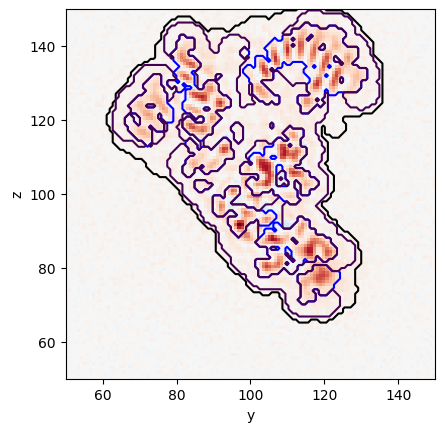

In [13]:
plot_map_slice(maps['New average half-maps (2.2 Å)'] / maps['New average half-maps (2.2 Å)'].grid.std(), "imshow", plane="yz", cmap="RdBu_r", norm=CenteredNorm())
plot_map_slice(
    Grid(masks['RNA-Shell'], edges=new_map.edges),
    "contour",
    plane="yz",
    levels=[0.5],
    colors='black',
    lw=0.5,
)
plot_map_slice(
    Grid(masks['RNA'], edges=new_map.edges),
    "contour",
    plane="yz",
    levels=[0.5],
    colors='blue',
    lw=0.5,
)
plot_map_slice(
    Grid(masks['Phosphates-Shell'], edges=new_map.edges),
    "contour",
    plane="yz",
    levels=[0.5],
)
plt.xlim(50, 150)
plt.ylim(50, 150)

Load generated maps

In [ ]:
from mg_sampling.density.grid import SparseGrid
# Replex

path = PROJECT_DIR / "density"

data = []
for filename in path.glob("*/all/replicate?_rep??.pkl"):
    weight_file = filename.with_stem(filename.stem + "_weight").with_suffix(".txt")
    if weight_file.exists():
        with open(weight_file, "r") as f:
            weight = float(f.read())
    else:
        weight = 1

    map_ = SparseGrid.load(filename)
    map_ = map_.to_dense().apply_tempfactor(30)

    data.append(
        dict(
            sim=filename.parent.parent.name,
            block=filename.stem,
            filename=str(filename),
            map=map_,
            weight=weight,
        )
    )
gen_maps = pd.DataFrame(data)
gen_maps["weight"] /= gen_maps.groupby("sim")["weight"].transform("sum")

In [15]:
import itertools
import functools
from mg_sampling.tools import bayesian_bootstrap
from scipy.stats import linregress
from tqdm import tqdm

results = []


def weighted_pearson_correlation(x, y, weights=None):
    return linregress(np.average(x, weights=weights), y).rvalue

def weighted_mutual_info(x, y, weights=None, n_subsamples=None):
    return mutual_info(np.average(x, weights=weights), y, n_subsamples=n_subsamples)



In [15]:

for k, mask in masks.items():
    for (simA, groupA), (simB, groupB) in tqdm(itertools.product(
        gen_maps.groupby("sim")[["map", "weight"]], repeat=2
    )):
        mapsA = groupA["map"].apply(lambda x: x.grid[mask]).to_numpy()
        mapsB = groupB["map"].apply(lambda x: x.grid[mask]).to_numpy()
        weightsA = groupA["weight"].to_numpy()
        weightsB = groupB["weight"].to_numpy()
        mapA = np.average(mapsA, weights=weightsA)
        mapB = np.average(mapsB, weights=weightsB)
        cc = linregress(
            mapA,
            mapB,
        ).rvalue

        cc_low, cc_high = bayesian_bootstrap(
            mapsA,
            functools.partial(weighted_pearson_correlation, y=mapB),
            weights=weightsA,
            n_resamples=50,
        ).confidence_interval

        results.append(
            {
                "simA": simA,
                "simB": simB,
                "mask": k,
                "cc": cc,
                "cc_low": cc_low,
                "cc_high": cc_high,
            }
        )


49it [00:46,  1.05it/s]
49it [00:19,  2.49it/s]
49it [00:31,  1.54it/s]
49it [00:34,  1.40it/s]
49it [00:23,  2.09it/s]


In [16]:
sim_labels = {
    "plain_md_7ez0_mMg_tip3p": "μMg (MD)",
    "plain_md_7ez0_nMg_tip3p": "nMg (MD)",
    "plain_md_7ez0_nMg_tip3p_soft": "nMg (MD-soft)",
    "plain_md_7ez0_noion_nMg_tip3p": "nMg (MD-denovo)",
    "plain_md_7ez0_nomg_mMg_tip3p": "no-Mg (MD)",
    "replex_7ez0_mMg_tip3p": "μMg (REx)",
    "replex_7ez0_noion_mMg_tip3p": "μMg (REx-denovo)",
}


In [17]:
sim_sim_results = pd.DataFrame(results).set_index(["simA", "simB", "mask"]).rename(index=sim_labels)

In [18]:
sim_sim_results[["cc"]].loc[:, :, "Shell"].unstack('simB').swaplevel(axis='columns').sort_index(axis='columns').style.background_gradient(vmin=0, vmax=1, cmap="Reds").format(precision=3)

simB,nMg (MD),nMg (MD-denovo),nMg (MD-soft),no-Mg (MD),μMg (MD),μMg (REx),μMg (REx-denovo)
,cc,cc,cc,cc,cc,cc,cc
simA,,,,,,,
nMg (MD),1.000,0.942,0.231,0.892,0.954,0.959,0.938
nMg (MD-denovo),0.942,1.000,0.228,0.917,0.928,0.931,0.950
nMg (MD-soft),0.231,0.228,1.000,0.226,0.227,0.233,0.232
no-Mg (MD),0.892,0.917,0.226,1.000,0.870,0.874,0.899
μMg (MD),0.954,0.928,0.227,0.870,1.000,0.941,0.896
μMg (REx),0.959,0.931,0.233,0.874,0.941,1.000,0.937
μMg (REx-denovo),0.938,0.950,0.232,0.899,0.896,0.937,1.000


In [19]:
sim_sim_results[["cc"]].loc[:, :, "Phosphates-Shell"].unstack('simB').swaplevel(axis='columns').sort_index(axis='columns').style.background_gradient(vmin=0, vmax=1, cmap="Reds").format(precision=3)

simB,nMg (MD),nMg (MD-denovo),nMg (MD-soft),no-Mg (MD),μMg (MD),μMg (REx),μMg (REx-denovo)
,cc,cc,cc,cc,cc,cc,cc
simA,,,,,,,
nMg (MD),1.000,0.935,0.195,0.880,0.952,0.956,0.930
nMg (MD-denovo),0.935,1.000,0.189,0.913,0.919,0.922,0.947
nMg (MD-soft),0.195,0.189,1.000,0.189,0.190,0.196,0.193
no-Mg (MD),0.880,0.913,0.189,1.000,0.857,0.858,0.891
μMg (MD),0.952,0.919,0.190,0.857,1.000,0.938,0.886
μMg (REx),0.956,0.922,0.196,0.858,0.938,1.000,0.929
μMg (REx-denovo),0.930,0.947,0.193,0.891,0.886,0.929,1.000


In [17]:
ref_maps = pd.Series(maps, name='map').rename_axis('desc').reset_index()

In [30]:
from mg_sampling.tools import bayesian_bootstrap
from mg_sampling.tools import bootstrap

results = []

for k, mask in masks.items():
    for sim, group in tqdm(gen_maps.groupby("sim")[["map", "weight"]]):
        for _, ref, refmap in ref_maps.itertuples():
            mapsA = group["map"].apply(lambda x: x.grid[mask]).to_numpy()
            weightsA = group["weight"].to_numpy()
            mapA = np.average(mapsA, weights=weightsA)
            mapB = refmap.grid[mask]
            cc = linregress(
                mapA,
                mapB,
            ).rvalue
            # mi = mutual_info(
            #     mapA,
            #     mapB,
            #     n_subsamples=10000,
            # )
            cc_low, cc_high = bootstrap(
                mapsA,
                functools.partial(weighted_pearson_correlation, y=mapB),
                weights=weightsA,
                n_resamples=100,
            ).confidence_interval
            # mi_stderr = bootstrap(
            #     mapsA,
            #     functools.partial(weighted_mutual_info, y=mapB, n_subsamples=10000),
            #     weights=weightsA,
            #     n_resamples=5,
            # ).standard_error

            results.append(
                {
                    "sim": sim,
                    "ref": ref,
                    "mask": k,
                    "cc": cc,
                    "cc_low": cc_low,
                    "cc_high": cc_high,
                    # "mi": mi,
                    # "mi_stderr": mi_stderr,
                }
            )

100%|██████████| 7/7 [00:42<00:00,  6.10s/it]


In [31]:
ref = ref_maps.iloc[1]["map"]
_, group = next(iter(gen_maps.groupby('sim')))
mapA = np.average(group["map"], weights=group["weight"].to_numpy())

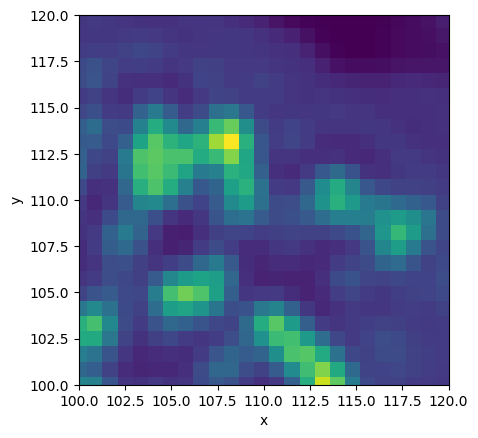

(100.0, 120.0)

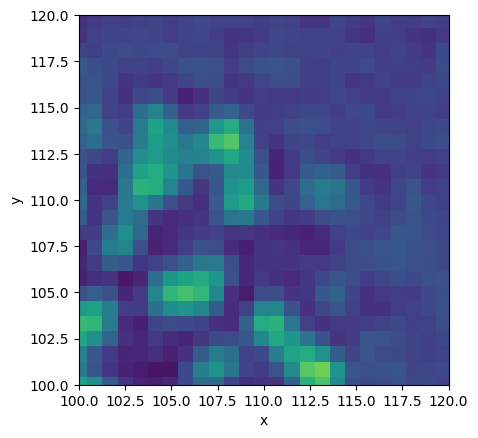

In [32]:
plot_map_slice(mapA)
plt.xlim(100, 120)
plt.ylim(100, 120)
plt.show()
plot_map_slice(ref)
plt.xlim(100, 120)
plt.ylim(100, 120)

In [2]:
pd.DataFrame(results).query("mask == 'RNA-Shell' and ref == 'New half-map 1 (2.2 Å)'").sort_values("cc").style.background_gradient(axis=None)

NameError: name 'pd' is not defined

In [34]:
pd.DataFrame(results).query("mask == 'Shell' and ref == 'New half-map 2 (2.2 Å)'").sort_values("cc").style.background_gradient(axis=None)

,sim,ref,mask,cc,cc_low,cc_high
255,plain_md_7ez0_nMg_tip3p_soft,New half-map 2 (2.2 Å),Shell,0.228355,0.208124,0.235679
277,plain_md_7ez0_nomg_mMg_tip3p,New half-map 2 (2.2 Å),Shell,0.295595,0.290141,0.299386
299,replex_7ez0_noion_mMg_tip3p,New half-map 2 (2.2 Å),Shell,0.312636,0.308165,0.313527
266,plain_md_7ez0_noion_nMg_tip3p,New half-map 2 (2.2 Å),Shell,0.313330,0.307611,0.314825
233,plain_md_7ez0_mMg_tip3p,New half-map 2 (2.2 Å),Shell,0.322051,0.317699,0.323003
288,replex_7ez0_mMg_tip3p,New half-map 2 (2.2 Å),Shell,0.323259,0.319254,0.324317
244,plain_md_7ez0_nMg_tip3p,New half-map 2 (2.2 Å),Shell,0.325168,0.321112,0.325366


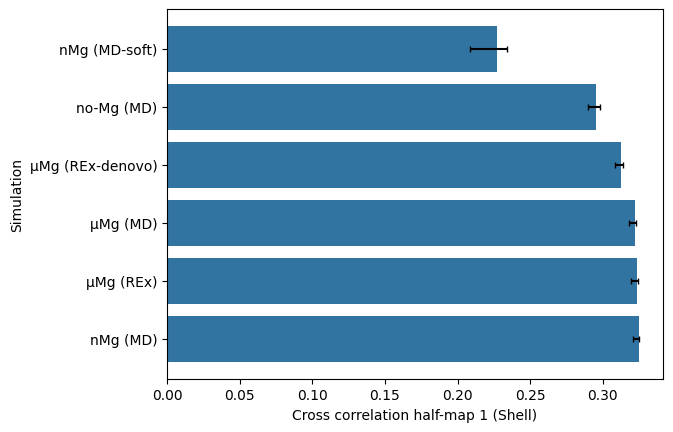

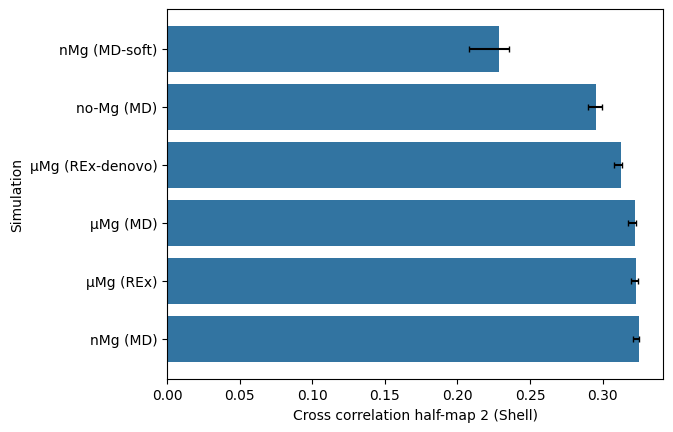

In [35]:
import seaborn as sns

for i in range(1,3):
    results = pd.DataFrame(results).query("sim != 'plain_md_7ez0_noion_nMg_tip3p'")
    results['sim_label'] = results['sim'].map(lambda s: "Local " + sim_labels[s.removesuffix('_local')] if s.endswith('local') else sim_labels[s])
    df = results.query(f"mask == 'Shell' and ref == 'New half-map {i} (2.2 Å)'").sort_values("cc")

    ax = sns.barplot(
        df,
        y='sim_label',
        x='cc',
    )

    y_coords = np.arange(len(df))

    x_data = df["cc"].clip(df["cc_low"], df["cc_high"])
    x_err = x_data - df["cc_low"], df["cc_high"] - x_data
    ax.errorbar(
        x=x_data,
        y=y_coords,
        xerr=x_err,
        color='black',
        capsize=2,
        linestyle='none',
    )

    plt.xlabel(f"Cross correlation half-map {i} (Shell)")
    plt.ylabel("Simulation")
    plt.show()

(0.0, 0.31894184255297975)

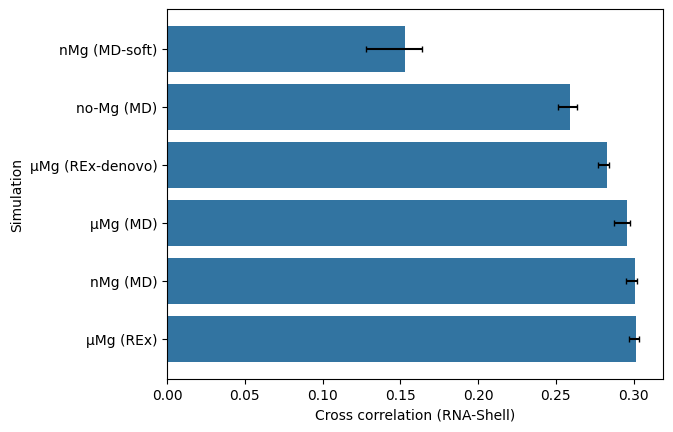

In [39]:
import seaborn as sns

results = pd.DataFrame(results)
results['sim_label'] = results['sim'].map(lambda s: "Local " + sim_labels[s.removesuffix('_local')] if s.endswith('local') else sim_labels[s])
df = results.query("mask == 'Phosphates-Shell' and ref == 'New average half-maps (2.2 Å)'").sort_values("cc")

ax = sns.barplot(
    df,
    y='sim_label',
    x='cc',
)

y_coords = np.arange(len(df))

x_data = df["cc"].clip(df["cc_low"], df["cc_high"])
x_err = x_data - df["cc_low"], df["cc_high"] - x_data
ax.errorbar(
    x=x_data,
    y=y_coords,
    xerr=x_err,
    color='black',
    capsize=2,
    linestyle='none',
)

plt.xlabel("Cross correlation (RNA-Shell)")
plt.ylabel("Simulation")
plt.xlim(0, None)